# Task 25 – Clustering Evaluation with Silhouette Score

Compare K-Means configurations without labeled targets. This notebook standardizes the customer features, calculates silhouette scores for several values of K, and selects the highest-scoring configuration.

The analysis uses `AnnualIncome_kUSD` and `SpendingScore`. `CustomerID` is an identifier and is excluded from clustering.

## 1. Install dependencies (if needed)

Run this cell once if these packages are not already installed: `!pip install pandas scikit-learn matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

FEATURES = ['AnnualIncome_kUSD', 'SpendingScore']
MIN_K = 2
MAX_K = 10

In [2]:
# Load the dataset and inspect the selected features.
customers = pd.read_csv(r'C:\Users\USER\OneDrive\Desktop\veda\AI-ML-Internship-Tasks\Task25\Mall_Customers.csv')
missing_columns = [column for column in FEATURES if column not in customers.columns]
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

features = customers[FEATURES].dropna()
if len(features) != len(customers):
    print(f'Skipped {len(customers) - len(features)} row(s) with missing feature values.')

print(f'{len(features)} complete customer records loaded.')
features.head()

36 complete customer records loaded.


,AnnualIncome_kUSD,SpendingScore
0,22,18
1,25,22
2,28,25
3,30,20
4,24,28


In [3]:
# Scale the features so income and spending score contribute comparably.
scaled_features = StandardScaler().fit_transform(features)
max_valid_k = min(MAX_K, len(features) - 1)
if MIN_K < 2 or MIN_K > max_valid_k:
    raise ValueError(f'Choose a K range starting at 2 and ending at no more than {len(features) - 1}.')

scores = {}
for k in range(MIN_K, max_valid_k + 1):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(scaled_features)
    scores[k] = silhouette_score(scaled_features, labels)

best_k = max(scores, key=scores.get)
score_table = pd.DataFrame({'K': list(scores.keys()), 'Silhouette Score': list(scores.values())})
score_table['Selected'] = score_table['K'].eq(best_k)
score_table.style.format({'Silhouette Score': '{:.4f}'})

C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,K,Silhouette Score,Selected
0,2,0.5781,False
1,3,0.8144,True
2,4,0.6658,False
3,5,0.5148,False
4,6,0.5241,False
5,7,0.5622,False
6,8,0.3858,False
7,9,0.3625,False
8,10,0.3739,False


Selected configuration: K=3 (silhouette score 0.8144)
A higher silhouette score generally indicates better-separated clusters.


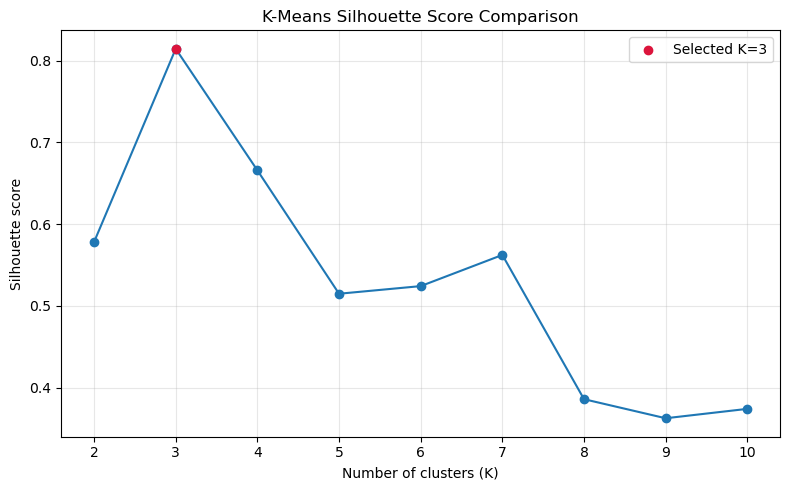

In [4]:
print(f'Selected configuration: K={best_k} (silhouette score {scores[best_k]:.4f})')
print('A higher silhouette score generally indicates better-separated clusters.')

plt.figure(figsize=(8, 5))
plt.plot(list(scores.keys()), list(scores.values()), marker='o')
plt.scatter([best_k], [scores[best_k]], color='crimson', zorder=3, label=f'Selected K={best_k}')
plt.xticks(list(scores.keys()))
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')
plt.title('K-Means Silhouette Score Comparison')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('silhouette_scores.png', dpi=150)
plt.show()

## Interpretation

The silhouette score ranges from -1 to 1. Higher values generally indicate that points are closer to their assigned cluster than to neighboring clusters; low or negative values can indicate overlap or poor separation. The best score within the tested K range is a useful guide, not proof that the configuration is best for every use case.

Silhouette evaluation is an internal clustering measure: it compares distances in feature space and does not need known labels. Classification evaluation instead compares predictions with target labels.